<a href="https://colab.research.google.com/github/karsarobert/DeepLearning2026/blob/main/PTE_DL07_EN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Learning 2026 – Lab 7
## Practical Machine Learning Workflows with Keras
### Regression, Multiclass Classification, and Anomaly Detection

### Overview
This notebook provides a complete hands-on overview of essential deep learning workflows in TensorFlow/Keras:
1. **Quick Syntax Cheat Sheet:** Core functions for data loading, scaling, model building, compilation, and evaluation.
2. **Task 1: Boston Housing Price Prediction (Regression)** – Predicting continuous numerical values.
3. **Task 2: Handwritten Digit Recognition (Multiclass Classification)** – Classifying MNIST images (0–9) using Dense layers.
4. **Task 3: Credit Card Fraud Detection (Anomaly Detection)** – Unsupervised anomaly detection using an Autoencoder.

### 1. Keras & Machine Learning Quick Reference

Below are the foundational patterns used throughout this lab.

In [1]:
# ------------------------------------------------------------
# DATA LOADING & PREPARATION SNIPPETS
# ------------------------------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks

# Train/Test Split Pattern
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Feature Scaling Pattern
# scaler = MinMaxScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_test_scaled = scaler.transform(X_test)

# One-Hot Encoding Pattern
# y_train_cat = tf.keras.utils.to_categorical(y_train, num_classes=10)

# Early Stopping Pattern
# early_stop = callbacks.EarlyStopping(min_delta=0.001, patience=15, restore_best_weights=True)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## Task 1: Housing Price Prediction (Regression)

**Dataset:** Boston Housing Dataset (13 demographic and structural features, target is median home value in $1000s).

**Workflow:**
1. Load raw data directly from the online source.
2. Standardize/scale input features to `[0, 1]` via `MinMaxScaler`.
3. Build a Multi-Layer Perceptron (MLP) regression network with ReLU activations and a single linear output neuron.
4. Compile using the `adam` optimizer and Mean Absolute Error (`mae`) loss.
5. Train with `EarlyStopping` to prevent overfitting, visualize the learning curve, and evaluate predictions.

In [2]:
# --- Load and prepare Boston Housing data ---
data_url = "http://lib.stat.cmu.edu/datasets/boston"
raw_df = pd.read_csv(data_url, sep=r"\s+", skiprows=22, header=None)

# Each sample is split across two rows in this format
X = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
y = raw_df.values[1::2, 2]

print(f"Feature matrix shape: {X.shape}")
print(f"Target vector shape:  {y.shape}")

# Split 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Normalize features to [0, 1] using training statistics only
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Define regression model explicitly
model_reg = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(1)  # Linear output for regression
], name="Boston_Housing_Regression")

model_reg.compile(optimizer='adam', loss='mae', metrics=['mae'])
model_reg.summary()

Feature matrix shape: (506, 13)
Target vector shape:  (506,)


Model: "Boston_Housing_Regression"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,009 (11.75 KB)

 Trainable params: 3,009 (11.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/500
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 146ms/step - loss: 22.6458 - mae: 22.6458 - val_loss: 21.0116 - val_mae: 21.0116
Epoch 2/500
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 22.0215 - mae: 22.0215 - val_loss: 20.2558 - val_mae: 20.2558
Epoch 3/500
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 21.1316 - mae: 21.1316 - val_loss: 19.1448 - val_mae: 19.1448
Epoch 4/500
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 19.8109 - mae: 19.8109 - val_loss: 17.4728 - val_mae: 17.4728
Epoch 5/500
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 17.8262 - mae: 17.8262 - val_loss: 15.0287 - val_mae: 15.0287
Epoch 6/500
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 15.1332 - mae: 15.1332 - val_loss: 11.9781 - val_mae: 11.9781
Epoch 7/500
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 12.1581 - mae: 12.1581 - val_loss: 9.5099 - val_mae: 9.5099
Epoch 8/500
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 9.9516 - mae: 9.9516 - val_loss: 8.3694 - val_mae: 8.3694
Epoch 9/500
13/13 ━━━━━━━━━━━━━━━

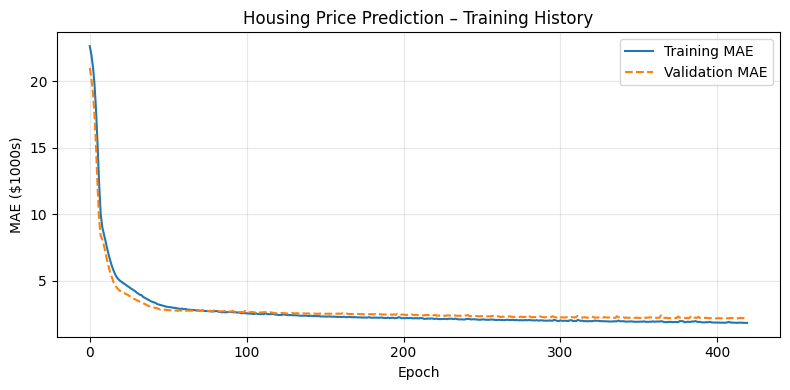

Minimum Validation MAE: 2.156k$


In [3]:
# Train regression model with Early Stopping
early_stop = callbacks.EarlyStopping(min_delta=0.001, patience=20, restore_best_weights=True)

history_reg = model_reg.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    epochs=500,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

# Plot training and validation loss
history_df = pd.DataFrame(history_reg.history)
plt.figure(figsize=(8, 4))
plt.plot(history_df['loss'], label='Training MAE')
plt.plot(history_df['val_loss'], label='Validation MAE', linestyle='--')
plt.title('Housing Price Prediction – Training History')
plt.xlabel('Epoch')
plt.ylabel('MAE ($1000s)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Minimum Validation MAE: {history_df['val_loss'].min():.3f}k$")

In [4]:
# Inference on first 5 test samples
sample_preds = model_reg.predict(X_test[:5])

print("Predicted Median Prices (first 5 test samples):")
print(sample_preds.flatten())
print("\nTrue Median Prices:")
print(y_test[:5])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 291ms/step
Predicted Median Prices (first 5 test samples):
[25.986332 33.600014 17.421902 23.61753  15.994587]

True Median Prices:
[23.6 32.4 13.6 22.8 16.1]


## Task 2: Handwritten Digit Recognition (Multiclass Classification)

**Dataset:** MNIST (60,000 train / 10,000 test grayscale 28x28 images of digits 0 through 9).

**Workflow:**
1. Load and scale pixel values to `[0, 1]`.
2. Reshape/flatten images from 2D `(28, 28)` to a 1D vector of length 784.
3. One-hot encode targets into 10-dimensional binary vectors.
4. Construct an MLP classifier with Dropout layers for regularization.
5. Output layer uses 10 units with `softmax` activation.
6. Compile using `categorical_crossentropy` and train with `EarlyStopping`.
7. Test sample inference and display prediction vs. ground truth.

In [5]:
# Load and preprocess MNIST dataset
(X_train_mnist, y_train_mnist), (X_test_mnist, y_test_mnist) = keras.datasets.mnist.load_data()

# Normalize pixel values
X_train_mnist = X_train_mnist.astype("float32") / 255.0
X_test_mnist = X_test_mnist.astype("float32") / 255.0

# Flatten 28x28 images to 784-element vectors
X_train_flat = X_train_mnist.reshape(-1, 784)
X_test_flat = X_test_mnist.reshape(-1, 784)

# One-hot encode targets
y_train_cat = tf.keras.utils.to_categorical(y_train_mnist, num_classes=10)
y_test_cat = tf.keras.utils.to_categorical(y_test_mnist, num_classes=10)

# Define classifier architecture
model_mnist = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
], name="MNIST_Classifier")

model_mnist.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model_mnist.summary()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "MNIST_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Train MNIST model
early_stop_mnist = callbacks.EarlyStopping(min_delta=0.001, patience=10, restore_best_weights=True)

history_mnist = model_mnist.fit(
    X_train_flat,
    y_train_cat,
    validation_data=(X_test_flat, y_test_cat),
    epochs=50,
    batch_size=256,
    callbacks=[early_stop_mnist],
    verbose=1
)

# Evaluate on test set
test_loss, test_acc = model_mnist.evaluate(X_test_flat, y_test_cat, verbose=0)
print(f"\nTest Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")

Epoch 1/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.8035 - loss: 0.6471 - val_accuracy: 0.9345 - val_loss: 0.2169
Epoch 2/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9173 - loss: 0.2846 - val_accuracy: 0.9513 - val_loss: 0.1594
Epoch 3/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9365 - loss: 0.2187 - val_accuracy: 0.9600 - val_loss: 0.1290
Epoch 4/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9456 - loss: 0.1869 - val_accuracy: 0.9642 - val_loss: 0.1130
Epoch 5/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9534 - loss: 0.1607 - val_accuracy: 0.9688 - val_loss: 0.1003
Epoch 6/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9584 - loss: 0.1429 - val_accuracy: 0.9707 - val_loss: 0.0968
Epoch 7/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9613 - loss: 0.1297 - val_accuracy: 0.9714 - val_loss: 0.0913
Epoch 8/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9647 - loss: 0.1197 - val_accuracy: 0

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 518ms/step


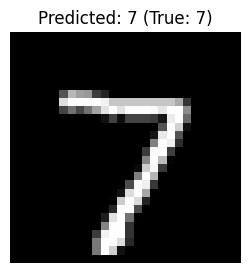

In [7]:
# Visualize sample test prediction
sample_idx = 0
sample_image = X_test_mnist[sample_idx]
sample_flat = X_test_flat[sample_idx:sample_idx+1]

pred_prob = model_mnist.predict(sample_flat)
predicted_digit = np.argmax(pred_prob)
true_digit = y_test_mnist[sample_idx]

plt.figure(figsize=(3, 3))
plt.imshow(sample_image, cmap='gray')
plt.title(f"Predicted: {predicted_digit} (True: {true_digit})")
plt.axis('off')
plt.show()

## Task 3: Credit Card Fraud Detection (Unsupervised Autoencoder Anomaly Detection)

**Premise:** In real-world fraud detection, fraudulent cases form a tiny minority (e.g., < 5%).
An **Autoencoder** is trained strictly on **normal transactions** (`label == 0`).
- Normal transactions are reconstructed with very low Mean Squared Error (MSE).
- Fraudulent/anomalous transactions deviate significantly and generate high reconstruction errors.
- A statistical threshold ($\mu + 2\sigma$) flags anomalies.

In [8]:
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# --- Generate synthetic transaction data ---
np.random.seed(42)
n_normal = 1000
n_features = 5

# Normal transactions
normal_tx = np.random.rand(n_normal, n_features) * 10
# Fraudulent transactions (shifted distribution)
fraud_tx = np.random.rand(int(n_normal * 0.05), n_features) * 10 + 5

data_tx = np.concatenate([normal_tx, fraud_tx])
labels_tx = np.array([0] * len(normal_tx) + [1] * len(fraud_tx))

# Normalize to [0, 1]
scaler_tx = MinMaxScaler()
data_tx_scaled = scaler_tx.fit_transform(data_tx)

# Stratified split into train/test
X_train_tx, X_test_tx, y_train_tx, y_test_tx = train_test_split(
    data_tx_scaled, labels_tx, test_size=0.2, random_state=42, stratify=labels_tx
)

# Filter training set to contain ONLY normal transactions (unsupervised paradigm)
X_train_normal = X_train_tx[y_train_tx == 0]
print(f"Normal training samples: {X_train_normal.shape[0]}")
print(f"Total test samples:     {X_test_tx.shape[0]}")

Normal training samples: 800
Total test samples:     210


In [9]:
# --- Build Autoencoder Model ---
input_dim = X_train_normal.shape[1]

autoencoder_fraud = keras.Sequential([
    layers.Input(shape=(input_dim,)),
    # Encoder
    layers.Dense(32, activation='relu', kernel_regularizer=keras.regularizers.l2(0.01)),
    layers.Dense(16, activation='relu', kernel_regularizer=keras.regularizers.l2(0.01)),
    # Decoder
    layers.Dense(32, activation='relu'),
    layers.Dense(input_dim, activation='linear')
], name="Transaction_Autoencoder")

autoencoder_fraud.compile(optimizer='adam', loss='mse')

# Train only on normal transactions
history_ae = autoencoder_fraud.fit(
    X_train_normal,
    X_train_normal,
    epochs=50,
    batch_size=32,
    validation_data=(X_test_tx, X_test_tx),
    verbose=0
)
print("Autoencoder training complete.")

Autoencoder training complete.


In [10]:
# Compute reconstruction error (MSE) on test transactions
reconstructions_tx = autoencoder_fraud.predict(X_test_tx)
mse_tx = np.mean(np.power(X_test_tx - reconstructions_tx, 2), axis=1)

# Determine anomaly threshold on normal training samples
train_recon = autoencoder_fraud.predict(X_train_normal)
train_mse = np.mean(np.power(X_train_normal - train_recon, 2), axis=1)
threshold_tx = np.mean(train_mse) + 2 * np.std(train_mse)
print(f"Reconstruction Error Threshold: {threshold_tx:.4f}")

# Flag anomalies (1 if error > threshold, 0 otherwise)
y_pred_tx = np.array([1 if e > threshold_tx else 0 for e in mse_tx])

# --- Evaluation ---
print("\nClassification Report:")
print(classification_report(y_test_tx, y_pred_tx, target_names=["Normal", "Fraud"]))

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Reconstruction Error Threshold: 0.0278

Classification Report:
              precision    recall  f1-score   support

      Normal       0.97      0.94      0.96       200
       Fraud       0.29      0.50      0.37        10

    accuracy                           0.92       210
   macro avg       0.63      0.72      0.66       210
weighted avg       0.94      0.92      0.93       210



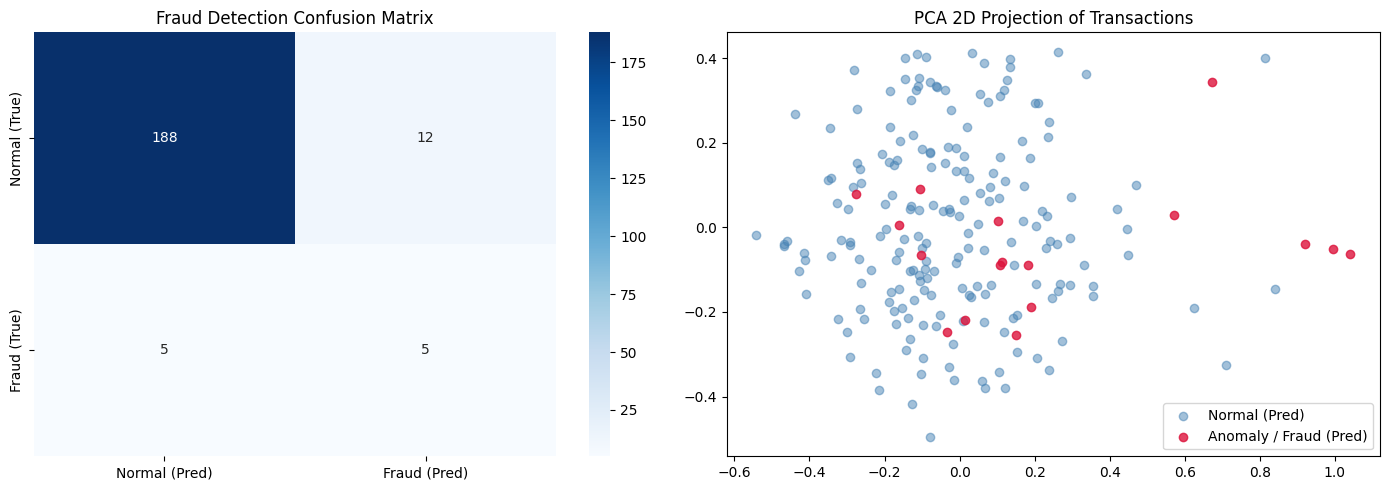

In [11]:
# --- Visualization: Confusion Matrix & PCA Projection ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Confusion Matrix
cm = confusion_matrix(y_test_tx, y_pred_tx)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Normal (Pred)', 'Fraud (Pred)'],
            yticklabels=['Normal (True)', 'Fraud (True)'])
axes[0].set_title('Fraud Detection Confusion Matrix')

# 2. PCA Scatter Plot
pca = PCA(n_components=2)
X_test_pca = pca.fit_transform(X_test_tx)

normal_idx = np.where(y_pred_tx == 0)[0]
fraud_idx = np.where(y_pred_tx == 1)[0]

axes[1].scatter(X_test_pca[normal_idx, 0], X_test_pca[normal_idx, 1], label="Normal (Pred)", alpha=0.5, c='steelblue')
axes[1].scatter(X_test_pca[fraud_idx, 0], X_test_pca[fraud_idx, 1], label="Anomaly / Fraud (Pred)", alpha=0.8, c='crimson')
axes[1].set_title('PCA 2D Projection of Transactions')
axes[1].legend()

plt.tight_layout()
plt.show()

### Summary & Key Takeaways

1. **Regression:** Linear output layer, unconstrained range, continuous error metric (`mae`).
2. **Multiclass Classification:** Softmax output layer, one-hot targets, `categorical_crossentropy` loss.
3. **Anomaly Detection:** Train Autoencoder strictly on clean/normal data; anomalies are identified via high reconstruction error ($> \mu + 2\sigma$).